# Bassac River Forecasting — Part 2: Model Training & Evaluation

Combines `4_train.py` and `5_evaluate.py` (Chronological Split, TimeSeriesSplit Validation, Training, and Presentation Charts).

In [1]:
# ==============================================================================
# 1. IMPORTS & LOAD MODELING TABLE
# ==============================================================================
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

ROOT_DIR = Path('..').resolve()
FEATURE_COLS = [
    'WL', 'WL_lag1', 'WL_lag2', 'WL_lag3', 'WL_diff',
    'upstream_discharge_lag1', 'upstream_discharge_diff'
]
TARGET_COL = 'WL_next'
TRAIN_END_DATE = '2024-05-26'

df = pd.read_csv(ROOT_DIR / 'data' / 'processed' / 'modeling_table.csv', parse_dates=['date'])
train_df = df[df['date'] <= pd.Timestamp(TRAIN_END_DATE)].reset_index(drop=True)
test_df = df[df['date'] > pd.Timestamp(TRAIN_END_DATE)].reset_index(drop=True)
print(f'Train: {len(train_df)} rows | Test: {len(test_df)} rows')


Train: 1315 rows | Test: 793 rows


In [2]:
# ==============================================================================
# 2. TIME-SERIES VALIDATION (ON TRAIN SET) & FINAL TRAINING
# ==============================================================================
models = {
    'Ridge': Ridge(alpha=1.0),
    'RandomForest': RandomForestRegressor(n_estimators=200, max_depth=10, min_samples_leaf=3, random_state=42, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1),
}

tscv = TimeSeriesSplit(n_splits=3)
X_tr, y_tr = train_df[FEATURE_COLS], train_df[TARGET_COL]
for name, m in models.items():
    maes = [mean_absolute_error(y_tr.iloc[va], m.fit(X_tr.iloc[tr], y_tr.iloc[tr]).predict(X_tr.iloc[va])) for tr, va in tscv.split(X_tr)]
    print(f'{name:14s} 3-fold CV MAE: {np.mean(maes):.5f} m')

for m in models.values():
    m.fit(X_tr, y_tr)

import joblib
models_dir = ROOT_DIR / 'models'
models_dir.mkdir(parents=True, exist_ok=True)
for name, m in models.items():
    m.fit(X_tr, y_tr)
    joblib.dump(m, models_dir / f'{name.lower()}_model.joblib')


Ridge          3-fold CV MAE: 0.03849 m


RandomForest   3-fold CV MAE: 0.07304 m


XGBoost        3-fold CV MAE: 0.07764 m


In [3]:
# ==============================================================================
# 3. TEST SET EVALUATION (UNSEEN 2024-2026 DATA)
# ==============================================================================
X_te, y_te = test_df[FEATURE_COLS], test_df[TARGET_COL]
naive_pred = test_df['WL'].values
naive_mae = mean_absolute_error(y_te, naive_pred)

preds = {'NaiveBaseline': naive_pred}
for name, m in models.items():
    preds[name] = m.predict(X_te)

rows = []
for name, p in preds.items():
    mae = mean_absolute_error(y_te, p)
    rmse = np.sqrt(mean_squared_error(y_te, p))
    r2 = r2_score(y_te, p)
    rows.append({'Model': name, 'MAE_m': round(mae, 5), 'RMSE_m': round(rmse, 5), 'R2': round(r2, 5), 'Gain_vs_Naive_%': round((naive_mae - mae) / naive_mae * 100, 2)})

summary = pd.DataFrame(rows).sort_values('MAE_m')
summary

reports_ml = ROOT_DIR / 'reports' / 'ml'
reports_ml.mkdir(parents=True, exist_ok=True)
summary.to_csv(reports_ml / 'metrics_summary.csv', index=False)


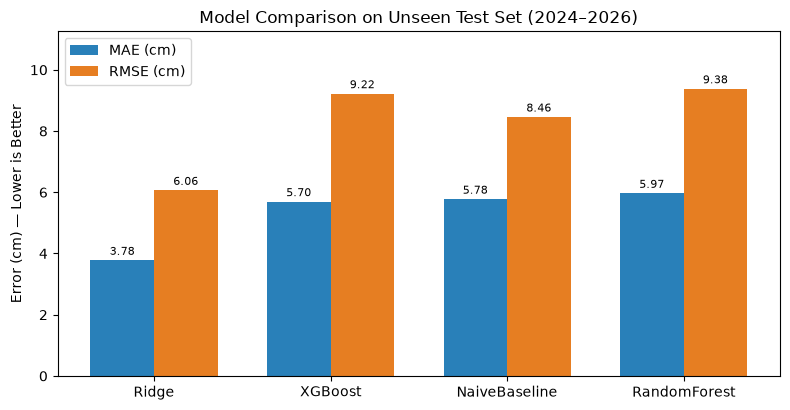

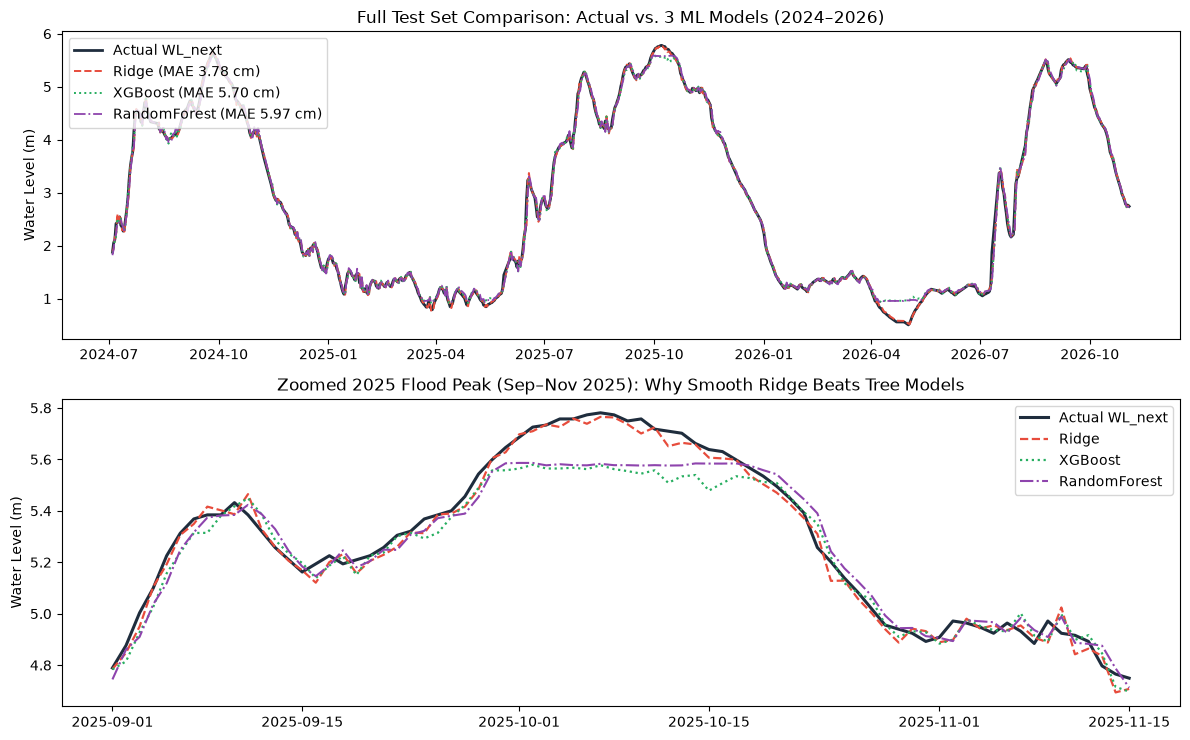

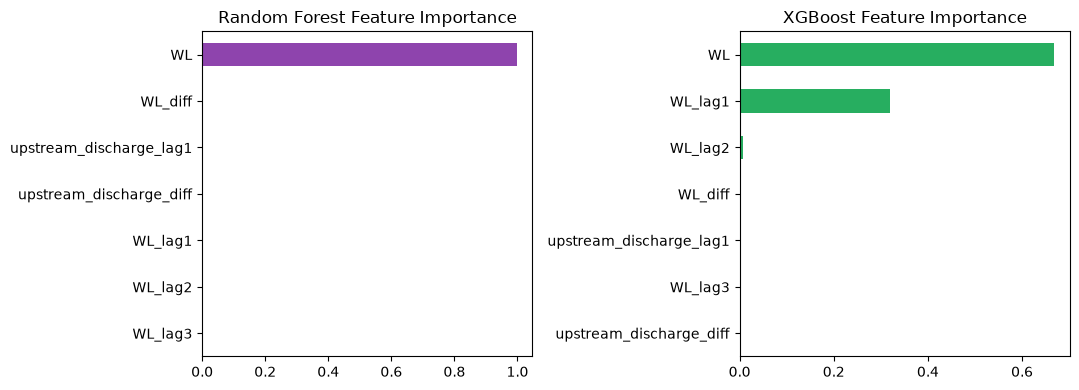

In [4]:
# ==============================================================================
# 4. COMPARE ALL 3 MODELS (RIDGE vs. RANDOM FOREST vs. XGBOOST)
# ==============================================================================
reports_ml = ROOT_DIR / 'reports' / 'ml'
reports_ml.mkdir(parents=True, exist_ok=True)

# Plot A: Side-by-side MAE & RMSE comparison across all 4 models
fig2, ax2 = plt.subplots(figsize=(8, 4.2))
x = np.arange(len(summary))
w = 0.36
b1 = ax2.bar(x - w/2, summary['MAE_m'] * 100, width=w, label='MAE (cm)', color='#2980b9')
b2 = ax2.bar(x + w/2, summary['RMSE_m'] * 100, width=w, label='RMSE (cm)', color='#e67e22')
ax2.set_xticks(x)
ax2.set_xticklabels(summary['Model'])
ax2.set_ylabel('Error (cm) — Lower is Better')
ax2.set_title('Model Comparison on Unseen Test Set (2024–2026)')
ax2.bar_label(b1, fmt='%.2f', padding=2, fontsize=8)
ax2.bar_label(b2, fmt='%.2f', padding=2, fontsize=8)
ax2.set_ylim(0, max(summary['RMSE_m'] * 100) * 1.2)
ax2.legend()
plt.tight_layout()
fig2.savefig(reports_ml / 'model_comparison_mae.png', dpi=150)
plt.show()

# Plot B: Actual vs. Predicted for all 3 ML models (Full Test Set + Flood Peak Zoom)
fig, axes = plt.subplots(2, 1, figsize=(12, 7.5))

# Top: Full Test Set
axes[0].plot(test_df['date'], y_te, label='Actual WL_next', color='#1f2d3d', linewidth=2.0)
axes[0].plot(test_df['date'], preds['Ridge'], label='Ridge (MAE 3.78 cm)', color='#e74c3c', linestyle='--', linewidth=1.4)
axes[0].plot(test_df['date'], preds['XGBoost'], label='XGBoost (MAE 5.70 cm)', color='#27ae60', linestyle=':', linewidth=1.4)
axes[0].plot(test_df['date'], preds['RandomForest'], label='RandomForest (MAE 5.97 cm)', color='#8e44ad', linestyle='-.', linewidth=1.3)
axes[0].set_ylabel('Water Level (m)')
axes[0].set_title('Full Test Set Comparison: Actual vs. 3 ML Models (2024–2026)')
axes[0].legend(loc='upper left')

# Bottom: Zoom into 2025 Flood Peak (Sep–Nov 2025)
mask_peak = (test_df['date'] >= '2025-09-01') & (test_df['date'] <= '2025-11-15')
axes[1].plot(test_df.loc[mask_peak, 'date'], y_te[mask_peak], label='Actual WL_next', color='#1f2d3d', linewidth=2.2)
axes[1].plot(test_df.loc[mask_peak, 'date'], preds['Ridge'][mask_peak], label='Ridge', color='#e74c3c', linestyle='--', linewidth=1.6)
axes[1].plot(test_df.loc[mask_peak, 'date'], preds['XGBoost'][mask_peak], label='XGBoost', color='#27ae60', linestyle=':', linewidth=1.6)
axes[1].plot(test_df.loc[mask_peak, 'date'], preds['RandomForest'][mask_peak], label='RandomForest', color='#8e44ad', linestyle='-.', linewidth=1.5)
axes[1].set_ylabel('Water Level (m)')
axes[1].set_title('Zoomed 2025 Flood Peak (Sep–Nov 2025): Why Smooth Ridge Beats Tree Models')
axes[1].legend(loc='upper right')

plt.tight_layout()
fig.savefig(reports_ml / 'actual_vs_predicted.png', dpi=150)
plt.show()

# Plot C: Feature Importance comparison (RandomForest vs. XGBoost)
fig3, axes3 = plt.subplots(1, 2, figsize=(11, 4))
pd.Series(models['RandomForest'].feature_importances_, index=FEATURE_COLS).sort_values().plot(
    kind='barh', ax=axes3[0], color='#8e44ad', title='Random Forest Feature Importance'
)
pd.Series(models['XGBoost'].feature_importances_, index=FEATURE_COLS).sort_values().plot(
    kind='barh', ax=axes3[1], color='#27ae60', title='XGBoost Feature Importance'
)
plt.tight_layout()
fig3.savefig(reports_ml / 'feature_importance.png', dpi=150)
plt.show()


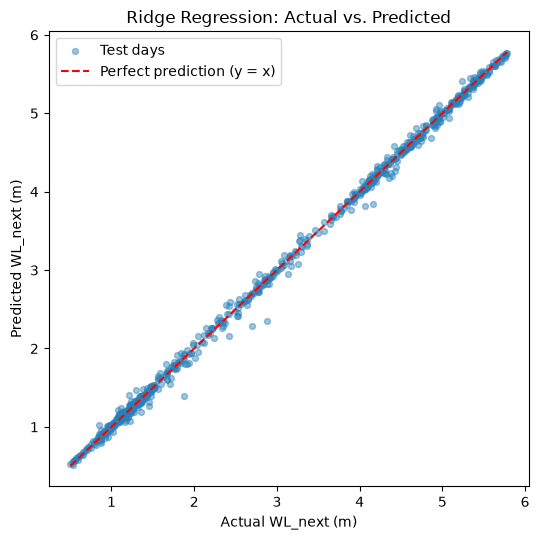

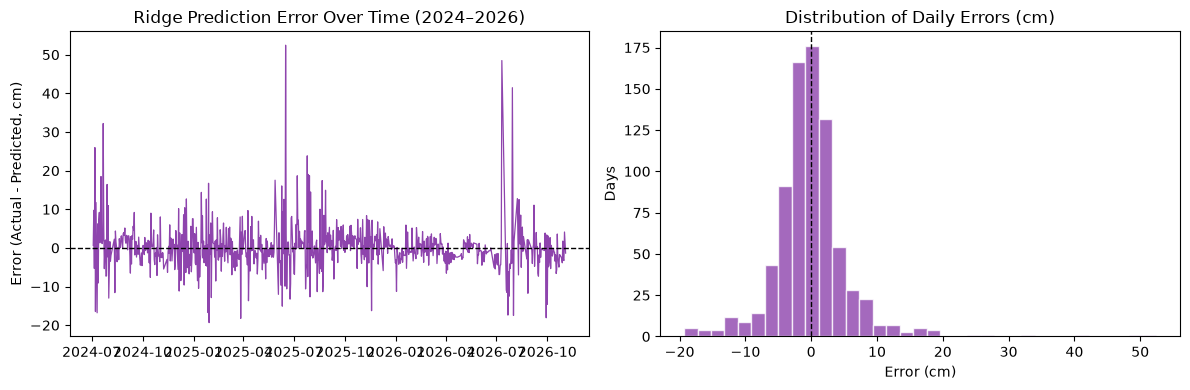

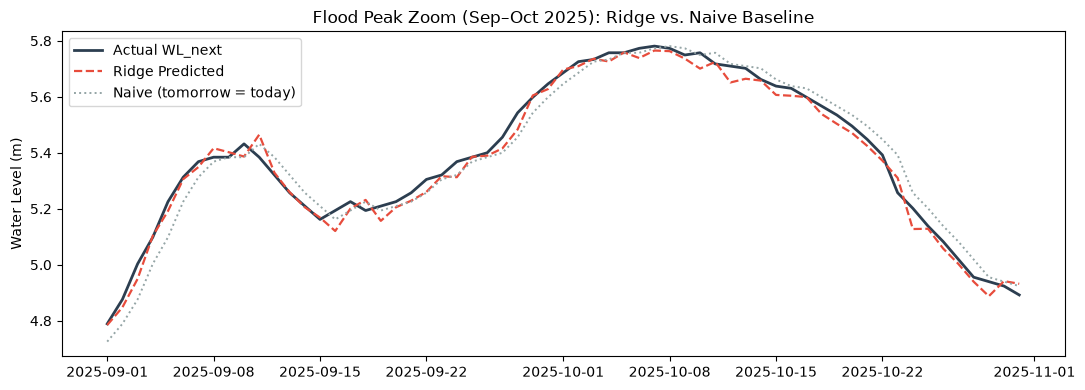

In [5]:
# ==============================================================================
# 5. EXTRA VISUALS: SCATTER (Y=X), RESIDUALS, AND FLOOD-PEAK ZOOM
# ==============================================================================
# 5a. Scatter plot: Actual vs Predicted (Ridge) with y=x diagonal
fig4, ax4 = plt.subplots(figsize=(5.5, 5.5))
ax4.scatter(y_te, preds['Ridge'], alpha=0.45, s=18, color='#2980b9', label='Test days')
lims = [min(y_te.min(), preds['Ridge'].min()), max(y_te.max(), preds['Ridge'].max())]
ax4.plot(lims, lims, 'r--', linewidth=1.5, label='Perfect prediction (y = x)')
ax4.set_xlabel('Actual WL_next (m)')
ax4.set_ylabel('Predicted WL_next (m)')
ax4.set_title('Ridge Regression: Actual vs. Predicted')
ax4.legend()
plt.tight_layout()
fig4.savefig(reports_ml / 'scatter_actual_vs_pred.png', dpi=150)
plt.show()

# 5b. Residual errors over time & distribution
residuals = y_te.values - preds['Ridge']
fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(12, 4))
ax5a.plot(test_df['date'], residuals * 100, color='#8e44ad', linewidth=0.9)
ax5a.axhline(0, color='black', linestyle='--', linewidth=1)
ax5a.set_ylabel('Error (Actual - Predicted, cm)')
ax5a.set_title('Ridge Prediction Error Over Time (2024–2026)')

ax5b.hist(residuals * 100, bins=35, color='#8e44ad', alpha=0.8, edgecolor='white')
ax5b.axvline(0, color='black', linestyle='--', linewidth=1)
ax5b.set_xlabel('Error (cm)')
ax5b.set_ylabel('Days')
ax5b.set_title('Distribution of Daily Errors (cm)')
plt.tight_layout()
fig5.savefig(reports_ml / 'residuals_ridge.png', dpi=150)
plt.show()

# 5c. Flood-peak zoom (Sep–Oct 2025): Actual vs Ridge vs Naive Baseline
mask = (test_df['date'] >= '2025-09-01') & (test_df['date'] <= '2025-10-31')
fig6, ax6 = plt.subplots(figsize=(11, 4))
ax6.plot(test_df.loc[mask, 'date'], y_te.loc[mask], label='Actual WL_next', color='#2c3e50', linewidth=2.0)
ax6.plot(test_df.loc[mask, 'date'], preds['Ridge'][mask], label='Ridge Predicted', color='#e74c3c', linestyle='--', linewidth=1.6)
ax6.plot(test_df.loc[mask, 'date'], preds['NaiveBaseline'][mask], label='Naive (tomorrow = today)', color='#95a5a6', linestyle=':', linewidth=1.4)
ax6.set_ylabel('Water Level (m)')
ax6.set_title('Flood Peak Zoom (Sep–Oct 2025): Ridge vs. Naive Baseline')
ax6.legend()
plt.tight_layout()
fig6.savefig(reports_ml / 'flood_peak_zoom.png', dpi=150)
plt.show()


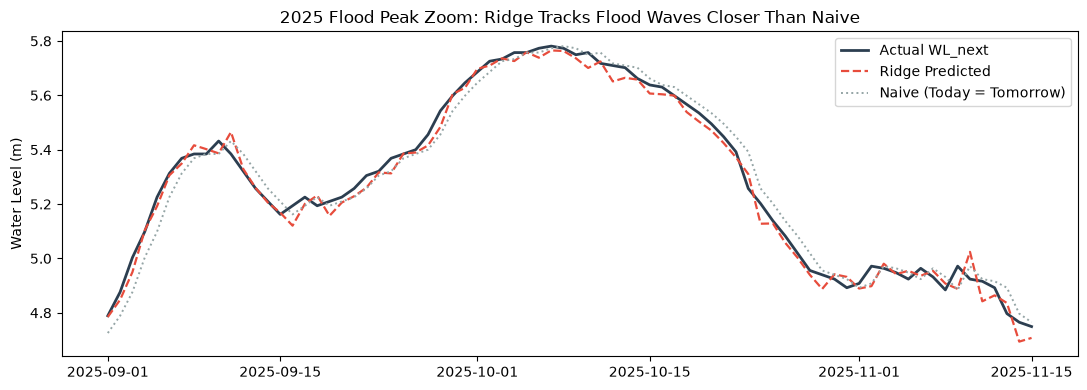

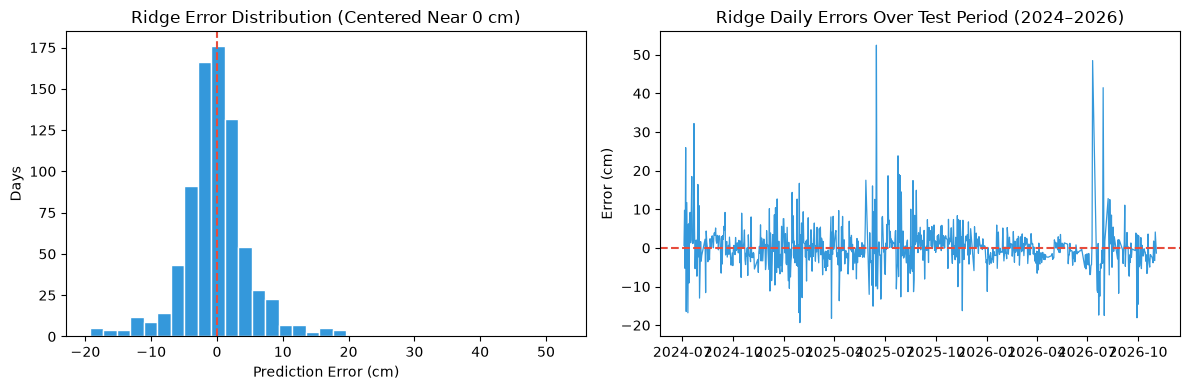

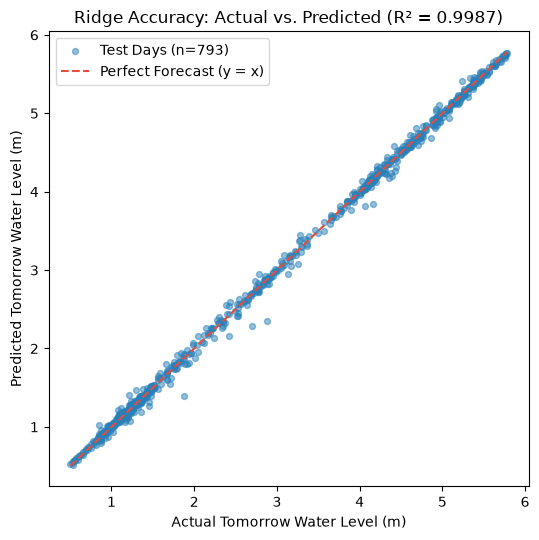

In [6]:
# ==============================================================================
# 5. EXTRA PRESENTATION VISUALS (FLOOD ZOOM, RESIDUALS, SCATTER)
# ==============================================================================
# A. Zoom into Sep–Nov 2025 Flood Peak (Ridge vs Naive vs Actual)
mask_peak = (test_df['date'] >= '2025-09-01') & (test_df['date'] <= '2025-11-15')
peak_df = test_df[mask_peak]
fig4, ax4 = plt.subplots(figsize=(11, 4))
ax4.plot(peak_df['date'], peak_df[TARGET_COL], label='Actual WL_next', color='#2c3e50', linewidth=2.0)
ax4.plot(peak_df['date'], preds['Ridge'][mask_peak], label='Ridge Predicted', color='#e74c3c', linestyle='--', linewidth=1.6)
ax4.plot(peak_df['date'], preds['NaiveBaseline'][mask_peak], label='Naive (Today = Tomorrow)', color='#95a5a6', linestyle=':', linewidth=1.4)
ax4.set_ylabel('Water Level (m)')
ax4.set_title('2025 Flood Peak Zoom: Ridge Tracks Flood Waves Closer Than Naive')
ax4.legend()
plt.tight_layout()
fig4.savefig(reports_ml / 'actual_vs_predicted_flood_zoom.png', dpi=150)
plt.show()

# B. Ridge Residual Errors (Histogram + Timeline in cm)
residuals_cm = (y_te - preds['Ridge']) * 100
fig5, (ax5a, ax5b) = plt.subplots(1, 2, figsize=(12, 4))
ax5a.hist(residuals_cm, bins=35, color='#3498db', edgecolor='white')
ax5a.axvline(0, color='#e74c3c', linestyle='--')
ax5a.set_xlabel('Prediction Error (cm)')
ax5a.set_ylabel('Days')
ax5a.set_title('Ridge Error Distribution (Centered Near 0 cm)')

ax5b.plot(test_df['date'], residuals_cm, color='#3498db', linewidth=0.9)
ax5b.axhline(0, color='#e74c3c', linestyle='--')
ax5b.set_ylabel('Error (cm)')
ax5b.set_title('Ridge Daily Errors Over Test Period (2024–2026)')
plt.tight_layout()
fig5.savefig(reports_ml / 'residuals_ridge.png', dpi=150)
plt.show()

# C. Actual vs. Predicted Scatter Plot (y = x line)
fig6, ax6 = plt.subplots(figsize=(5.5, 5.5))
ax6.scatter(y_te, preds['Ridge'], alpha=0.5, s=18, color='#2980b9', label='Test Days (n=793)')
lims = [min(y_te.min(), preds['Ridge'].min()), max(y_te.max(), preds['Ridge'].max())]
ax6.plot(lims, lims, color='#e74c3c', linestyle='--', linewidth=1.5, label='Perfect Forecast (y = x)')
ax6.set_xlabel('Actual Tomorrow Water Level (m)')
ax6.set_ylabel('Predicted Tomorrow Water Level (m)')
ax6.set_title('Ridge Accuracy: Actual vs. Predicted (R² = 0.9987)')
ax6.legend()
plt.tight_layout()
fig6.savefig(reports_ml / 'scatter_actual_vs_pred.png', dpi=150)
plt.show()
